In [ ]:

import pandas as pd
from sklearn.preprocessing import StandardScaler

# 1. Load the dataset (fixed the double .parquet typo)
df = pd.read_parquet('../data/network_intrusion_clustering.parquet')

# 2. Drop Label — clustering is unsupervised, Label used only for evaluation
# Notice we are using 'df' here, not 'df_clustering'
X = df.drop(columns=['Label'])
y = df['Label']  # saved for post-hoc interpretation

# 3. Standardize features (zero mean, unit variance)
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

print(f"Feature matrix shape : {X_scaled.shape}")
print(f"Label series shape   : {y.shape}")
print("All scaled with standart scaler ")

Feature matrix shape : (50420, 25)
Label series shape   : (50420,)
All scaled with standart scaler 


In [3]:
import json

# 1. Load the label mapping JSON file
# (Make sure the path matches your folder structure)
with open('../data/label_mapping.json', 'r') as f:
    label_mapping = json.load(f)

# 2. Reverse the dictionary so numbers are the keys
# JSON saves keys as strings, so we convert the value 'v' to an integer
inverse_mapping = {int(v): k for k, v in label_mapping.items()}

# 3. Create a permanent 'Label_Name' column for easy evaluation later
df['Label_Name'] = df['Label'].map(inverse_mapping)

print("Label mapping loaded!")

Label mapping loaded!


## K-Means

k= 2 | Inertia:    1061440.9 | Silhouette: 0.5135 | Davies-Bouldin: 1.6709
k= 3 | Inertia:     985327.9 | Silhouette: 0.6301 | Davies-Bouldin: 1.2235
k= 4 | Inertia:     896926.3 | Silhouette: 0.4937 | Davies-Bouldin: 1.3371
k= 5 | Inertia:     813464.2 | Silhouette: 0.4205 | Davies-Bouldin: 1.4093
k= 6 | Inertia:     750604.5 | Silhouette: 0.4320 | Davies-Bouldin: 1.2638
k= 7 | Inertia:     687251.9 | Silhouette: 0.4329 | Davies-Bouldin: 1.1453
k= 8 | Inertia:     653142.5 | Silhouette: 0.4562 | Davies-Bouldin: 1.0633
k= 9 | Inertia:     598468.7 | Silhouette: 0.4756 | Davies-Bouldin: 1.0775
k=10 | Inertia:     564408.3 | Silhouette: 0.4640 | Davies-Bouldin: 1.0100


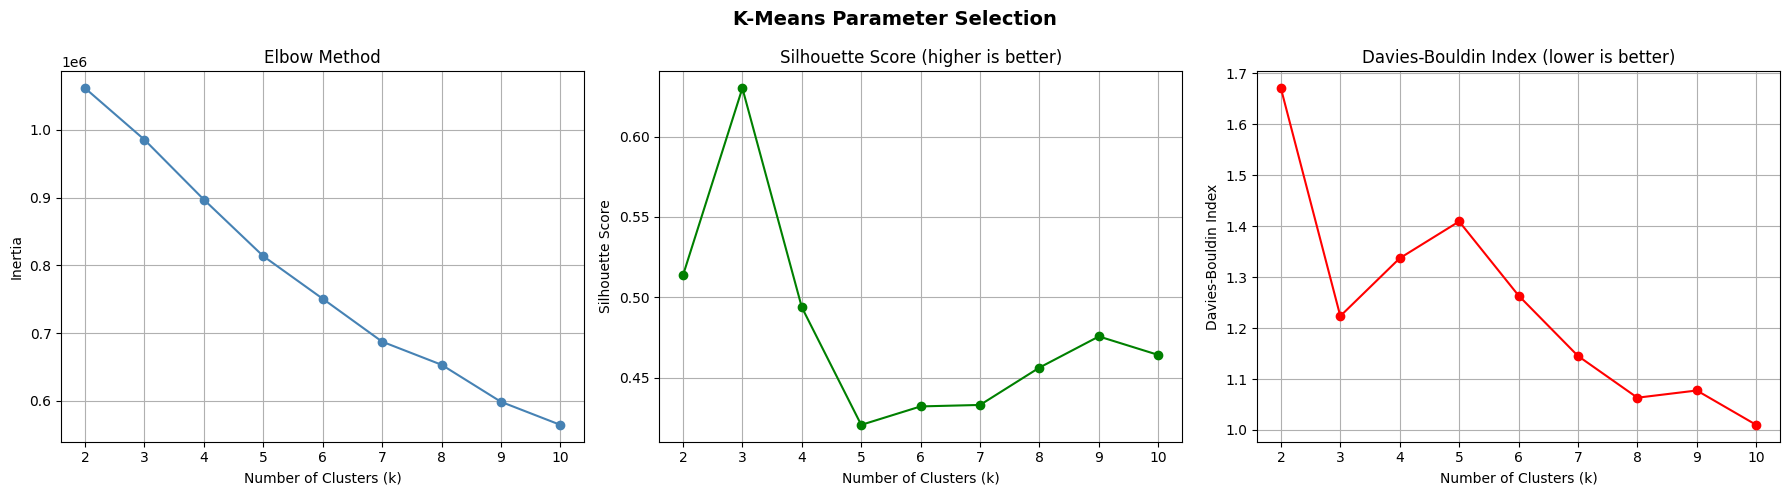


  Best k selected    : 3
   Silhouette Score  : 0.6301
   Davies-Bouldin    : 1.2235
   ARI               : 0.0872  (1.0 = perfect, 0 = random)
   NMI               : 0.0652  (1.0 = perfect, 0 = no mutual info)

 K-Means complete. Cluster labels saved to df.


In [ ]:
# =============================================================
# K-MEANS CLUSTERING
# =============================================================
import numpy as np
import matplotlib.pyplot as plt
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score, davies_bouldin_score, adjusted_rand_score, normalized_mutual_info_score

k_range = range(2, 15)

inertias          = []
silhouette_scores = []
db_scores         = []

for k in k_range:
    km = KMeans(n_clusters=k, random_state=42, n_init=10)
    labels = km.fit_predict(X_scaled)

    inertias.append(km.inertia_)
    silhouette_scores.append(silhouette_score(X_scaled, labels))
    db_scores.append(davies_bouldin_score(X_scaled, labels))

    print(f"k={k:2d} | Inertia: {km.inertia_:>12.1f} | "
          f"Silhouette: {silhouette_scores[-1]:.4f} | "
          f"Davies-Bouldin: {db_scores[-1]:.4f}")

# -------------------------------------------------------------
# Plots
# -------------------------------------------------------------
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

axes[0].plot(k_range, inertias, marker='o', color='steelblue')
axes[0].set_title('Elbow Method')
axes[0].set_xlabel('Number of Clusters (k)')
axes[0].set_ylabel('Inertia')
axes[0].grid(True)

axes[1].plot(k_range, silhouette_scores, marker='o', color='green')
axes[1].set_title('Silhouette Score (higher is better)')
axes[1].set_xlabel('Number of Clusters (k)')
axes[1].set_ylabel('Silhouette Score')
axes[1].grid(True)

axes[2].plot(k_range, db_scores, marker='o', color='red')
axes[2].set_title('Davies-Bouldin Index (lower is better)')
axes[2].set_xlabel('Number of Clusters (k)')
axes[2].set_ylabel('Davies-Bouldin Index')
axes[2].grid(True)

plt.suptitle('K-Means Parameter Selection', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()

# -------------------------------------------------------------
# Best k & Final Model
# -------------------------------------------------------------
best_k = silhouette_scores.index(max(silhouette_scores)) + 2

km_best = KMeans(n_clusters=best_k, random_state=42, n_init=10)
kmeans_labels = km_best.fit_predict(X_scaled)

# Save labels back to df
df['KMeans_Cluster'] = kmeans_labels

# -------------------------------------------------------------
# Evaluation vs Ground Truth (Label)
# -------------------------------------------------------------
ari = adjusted_rand_score(y, kmeans_labels)
nmi = normalized_mutual_info_score(y, kmeans_labels)

print(f"\n  Best k selected    : {best_k}")
print(f"   Silhouette Score  : {max(silhouette_scores):.4f}")
print(f"   Davies-Bouldin    : {db_scores[best_k - 2]:.4f}")
print(f"   ARI               : {ari:.4f}  (1.0 = perfect, 0 = random)")
print(f"   NMI               : {nmi:.4f}  (1.0 = perfect, 0 = no mutual info)")

print("\n K-Means complete. Cluster labels saved to df.")

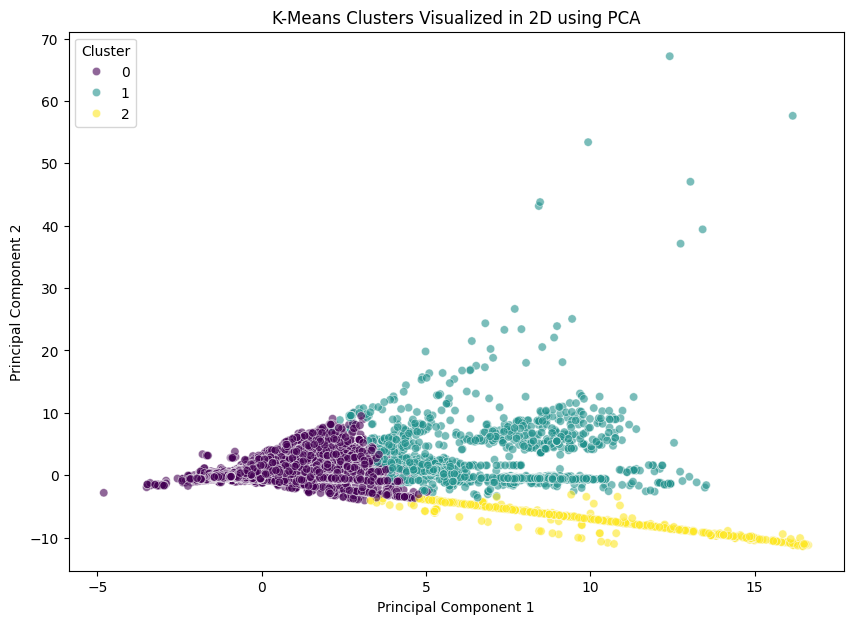

In [4]:
from sklearn.decomposition import PCA
import seaborn as sns

# Squash the 25 dimensions down to 2 dimensions (Principal Components)
pca = PCA(n_components=2)
X_pca = pca.fit_transform(X_scaled)

# Plot the PCA results, coloring the dots by their K-Means cluster
plt.figure(figsize=(10, 7))
sns.scatterplot(x=X_pca[:, 0], y=X_pca[:, 1], hue=df['KMeans_Cluster'], palette='viridis', alpha=0.6)
plt.title('K-Means Clusters Visualized in 2D using PCA')
plt.xlabel('Principal Component 1')
plt.ylabel('Principal Component 2')
plt.legend(title='Cluster')
plt.show()

In [5]:
# Create a table comparing the true label names to the K-Means clusters
kmeans_analysis = pd.crosstab(
    index=df['Label_Name'], 
    columns=df['KMeans_Cluster'], 
    margins=True
)

print("K-Means Cluster Distribution vs. True Labels:")
display(kmeans_analysis)

K-Means Cluster Distribution vs. True Labels:


KMeans_Cluster,0,1,2,All
Label_Name,,,,
BENIGN,39860,1409,578,41847
Bot,39,0,0,39
DDoS,2560,0,0,2560
DoS GoldenEye,182,1,23,206
DoS Hulk,2550,903,1,3454
DoS Slowhttptest,78,27,0,105
DoS slowloris,40,40,28,108
FTP-Patator,118,0,0,118
Heartbleed,1,6,0,7


## Hierarchical

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import AgglomerativeClustering
from sklearn.metrics import silhouette_score, davies_bouldin_score

# -------------------------------------------------------------
# 1. Sample and Scale Data from Scratch (Corrected)
# -------------------------------------------------------------
# Clean up column names to remove hidden spaces (fixes the 'Label' issue)
df.columns = df.columns.str.strip()

# Sample 10,000 rows to prevent MemoryErrors
df_sample = df.sample(n=10000, random_state=42).copy()

# Separate features (X) from the target label
if 'Label' in df_sample.columns:
    X_sample = df_sample.drop(columns=['Label'])
    y_sample = df_sample['Label']
else:
    print("Warning: 'Label' column still not found. Check your dataframe columns.")
    X_sample = df_sample.copy()
    y_sample = None

# SAFETY NET: Force X_sample to only keep numeric columns 
# (drops Timestamps, IPs, or any other leftover text)
X_sample = X_sample.select_dtypes(include=[np.number])

# Scale the sampled data from scratch
scaler = StandardScaler()
X_sample_scaled = scaler.fit_transform(X_sample)

print(f"Data successfully scaled. Shape: {X_sample_scaled.shape}")

# -------------------------------------------------------------
# 2. Evaluate Linkages and k
# -------------------------------------------------------------
k_range = range(2, 11)
linkages = ['ward', 'complete', 'average', 'single']

results = []

print("Evaluating Hierarchical Clustering...\n")
print(f"{'Linkage':<10} | {'k':<3} | {'Silhouette':<12} | {'Davies-Bouldin'}")
print("-" * 50)

for linkage in linkages:
    for k in k_range:
        # Ward requires euclidean distance; the others can use different metrics, 
        # but sticking to euclidean keeps the comparison standardized.
        hc = AgglomerativeClustering(n_clusters=k, metric='euclidean', linkage=linkage)
        labels = hc.fit_predict(X_sample_scaled)
        
        # Calculate internal metrics
        sil_score = silhouette_score(X_sample_scaled, labels)
        db_score = davies_bouldin_score(X_sample_scaled, labels)
        
        results.append({
            'linkage': linkage,
            'k': k,
            'silhouette': sil_score,
            'davies_bouldin': db_score
        })
        
        print(f"{linkage:<10} | {k:<3} | {sil_score:<12.4f} | {db_score:.4f}")
    print("-" * 40)

# Convert to DataFrame for easy querying
results_df = pd.DataFrame(results)

# -------------------------------------------------------------
# 3. Find Best Parameters & Save Final Model
# -------------------------------------------------------------
# Automatically find the parameters that yielded the highest Silhouette score
best_idx = results_df['silhouette'].idxmax()
best_k = int(results_df.loc[best_idx, 'k'])
best_linkage = results_df.loc[best_idx, 'linkage']
best_silhouette = results_df.loc[best_idx, 'silhouette']

print("\n" + "=" * 40)
print("BEST MODEL SELECTED")
print("=" * 40)
print(f" Best Linkage : {best_linkage}")
print(f" Best k       : {best_k}")
print(f" Silhouette   : {best_silhouette:.4f}")

# Run the final model with the absolute best parameters
hc_best = AgglomerativeClustering(n_clusters=best_k, metric='euclidean', linkage=best_linkage)
hc_best_labels = hc_best.fit_predict(X_sample_scaled)

# Save the labels back to the sampled dataframe for later use (like PCA)
df_sample['HC_Cluster'] = hc_best_labels

print("\nHierarchical Clustering complete. Best labels saved to 'df_sample'.")

Data successfully scaled. Shape: (10000, 25)
Evaluating Hierarchical Clustering...

Linkage    | k   | Silhouette   | Davies-Bouldin
--------------------------------------------------
ward       | 2   | 0.4905       | 1.7724
ward       | 3   | 0.4855       | 1.4625
ward       | 4   | 0.4842       | 1.1017
ward       | 5   | 0.4783       | 1.0593
ward       | 6   | 0.4736       | 0.9848
ward       | 7   | 0.4062       | 1.1695
ward       | 8   | 0.4075       | 1.0564
ward       | 9   | 0.4152       | 1.0201
ward       | 10  | 0.4393       | 1.0309
----------------------
complete   | 2   | 0.9567       | 0.0292
complete   | 3   | 0.8238       | 0.2269


KeyboardInterrupt: 

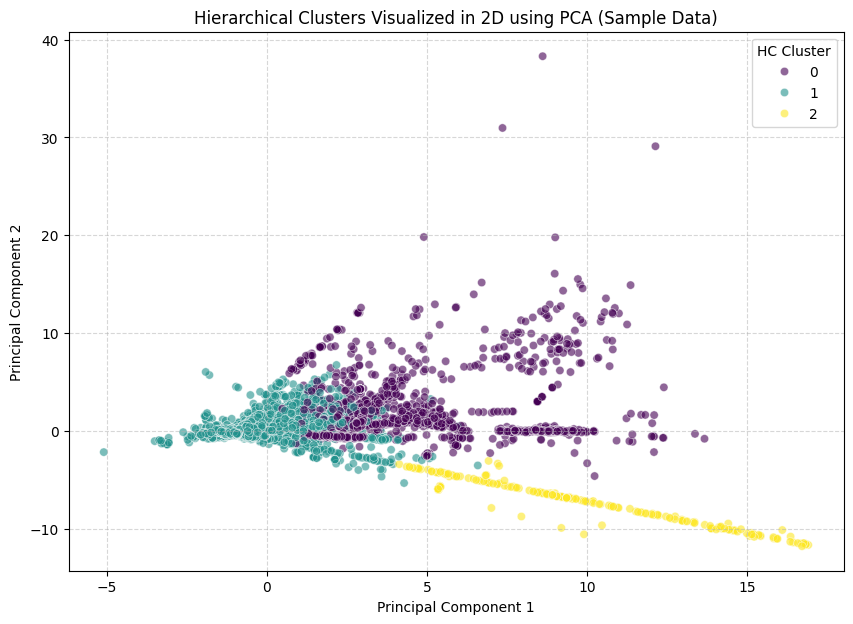

In [ ]:
from sklearn.decomposition import PCA
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.cluster import AgglomerativeClustering

# 1. Fit your final Hierarchical Clustering model on the sample
# (We use 'ward' or whatever your winning linkage_method was)
hc_final = AgglomerativeClustering(n_clusters=3, linkage='ward')
df_sample['HC_Cluster'] = hc_final.fit_predict(X_sample_scaled)

# 2. Squash the dimensions down to 2 dimensions using PCA
pca = PCA(n_components=2, random_state=42)
X_pca_sample = pca.fit_transform(X_sample_scaled)

# 3. Plot the PCA results, coloring the dots by their Hierarchical Cluster
plt.figure(figsize=(10, 7))
sns.scatterplot(
    x=X_pca_sample[:, 0], 
    y=X_pca_sample[:, 1], 
    hue=df_sample['HC_Cluster'], 
    palette='viridis', 
    alpha=0.6
)
plt.title('Hierarchical Clusters Visualized in 2D using PCA (Sample Data)')
plt.xlabel('Principal Component 1')
plt.ylabel('Principal Component 2')
plt.legend(title='HC Cluster')
plt.grid(True, linestyle='--', alpha=0.5)
plt.show()

In [8]:
# Map the numeric labels to their original string names using your inverse_mapping dict
df_sample['Label_Name'] = df_sample['Label'].map(inverse_mapping)

# Create a cross-tabulation table comparing string labels to the Hierarchical clusters
hc_analysis = pd.crosstab(
    index=df_sample['Label_Name'], 
    columns=df_sample['HC_Cluster'], 
    margins=True
)

print("Hierarchical Cluster Distribution vs. True Label Names (Sample Data):")
display(hc_analysis)

Hierarchical Cluster Distribution vs. True Label Names (Sample Data):


HC_Cluster,0,1,2,All
Label_Name,,,,
BENIGN,1367,15015,243,16625
Bot,0,19,0,19
DDoS,116,899,0,1015
DoS GoldenEye,3,74,4,81
DoS Hulk,1049,313,0,1362
DoS Slowhttptest,27,11,0,38
DoS slowloris,15,18,9,42
FTP-Patator,0,43,0,43
Heartbleed,4,0,0,4


## DBScan

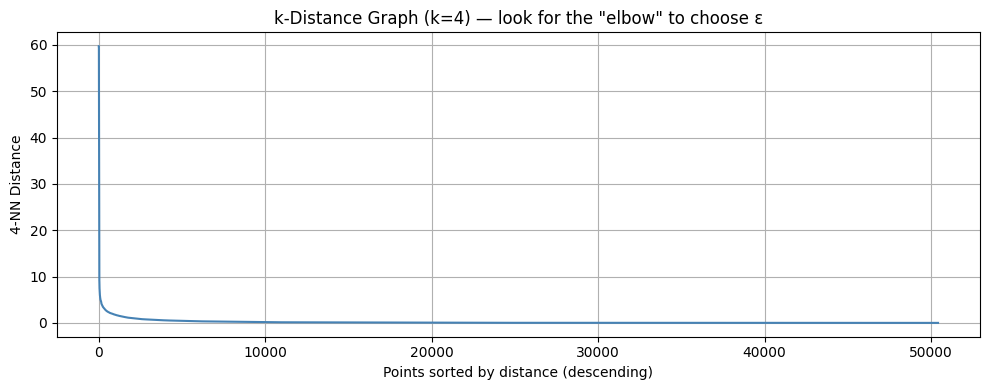

   eps | min_samp | n_clusters |  noise_% |  Silhouette |  Davies-Bouldin
------------------------------------------------------------------------
   0.3 |        5 |        314 |    13.1% | 0.10597939701078024 | 0.5508720708954367
   0.3 |       10 |        173 |    16.1% | 0.34569125989203253 | 0.512745121754624
   0.3 |       20 |        109 |    20.4% | 0.5080537556816438 | 0.45536067231376726
   0.3 |       50 |         55 |    27.1% | 0.6868455929297037 | 0.4290688852443452
   0.5 |        5 |        238 |     8.3% | 0.12043211166411902 | 0.5498919408429626
   0.5 |       10 |        124 |    10.9% | 0.23722445517762972 | 0.5447625584757096
   0.5 |       20 |         77 |    14.0% | 0.47940922664900826 | 0.5075169771730196
   0.5 |       50 |         44 |    19.2% | 0.5687900037825463 | 0.49411536896637337
   0.8 |        5 |        159 |     4.9% | 0.1160961707902614 | 0.5074468344462586
   0.8 |       10 |         77 |     6.7% | 0.3131364431799057 | 0.4684729897081908
   0.8 

KeyboardInterrupt: 

In [7]:
# =============================================================
# DBSCAN CLUSTERING
# =============================================================
import numpy as np
import matplotlib.pyplot as plt
from sklearn.cluster import DBSCAN
from sklearn.neighbors import NearestNeighbors
from sklearn.metrics import silhouette_score, davies_bouldin_score, adjusted_rand_score, normalized_mutual_info_score
from sklearn.decomposition import PCA
from itertools import product

# -------------------------------------------------------------
# Step 1: k-distance plot to estimate a good epsilon
# -------------------------------------------------------------
# Use k = min_samples - 1 (commonly 4) for the k-NN distance plot
k_nn = 4
nbrs = NearestNeighbors(n_neighbors=k_nn).fit(X_scaled)
distances, _ = nbrs.kneighbors(X_scaled)
k_distances = np.sort(distances[:, -1])[::-1]   # sort descending

plt.figure(figsize=(10, 4))
plt.plot(k_distances, color='steelblue')
plt.title(f'k-Distance Graph (k={k_nn}) — look for the "elbow" to choose ε')
plt.xlabel('Points sorted by distance (descending)')
plt.ylabel(f'{k_nn}-NN Distance')
plt.grid(True)
plt.tight_layout()
plt.show()

# -------------------------------------------------------------
# Step 2: Grid search over (eps, min_samples)
# -------------------------------------------------------------
eps_values        = [0.3, 0.5, 0.8, 1.0, 1.5, 2.0]
min_samples_values = [5, 10, 20, 50]

results = []

print(f"{'eps':>6} | {'min_samp':>8} | {'n_clusters':>10} | {'noise_%':>8} | {'Silhouette':>11} | {'Davies-Bouldin':>15}")
print("-" * 72)

for eps, min_samp in product(eps_values, min_samples_values):
    db = DBSCAN(eps=eps, min_samples=min_samp, n_jobs=-1)
    labels = db.fit_predict(X_scaled)

    n_clusters = len(set(labels)) - (1 if -1 in labels else 0)
    noise_pct  = np.sum(labels == -1) / len(labels) * 100

    # Need at least 2 clusters and some non-noise points to score
    non_noise_mask = labels != -1
    if n_clusters >= 2 and non_noise_mask.sum() > 0:
        sil = silhouette_score(X_scaled[non_noise_mask], labels[non_noise_mask])
        dbi = davies_bouldin_score(X_scaled[non_noise_mask], labels[non_noise_mask])
    else:
        sil, dbi = np.nan, np.nan

    results.append({
        'eps': eps, 'min_samples': min_samp,
        'n_clusters': n_clusters, 'noise_pct': noise_pct,
        'silhouette': sil, 'davies_bouldin': dbi
    })
    print(f"{eps:>6.1f} | {min_samp:>8} | {n_clusters:>10} | {noise_pct:>7.1f}% | "
          f"{sil if not np.isnan(sil) else 'N/A':>11} | "
          f"{dbi if not np.isnan(dbi) else 'N/A':>15}")

# -------------------------------------------------------------
# Step 3: Pick best config (highest Silhouette, noise < 30%)
# -------------------------------------------------------------
valid = [r for r in results if not np.isnan(r['silhouette']) and r['noise_pct'] < 30]
best  = max(valid, key=lambda r: r['silhouette'])

print(f"\n  Best configuration:")
print(f"   eps          : {best['eps']}")
print(f"   min_samples  : {best['min_samples']}")
print(f"   n_clusters   : {best['n_clusters']}")
print(f"   Noise points : {best['noise_pct']:.1f}%")
print(f"   Silhouette   : {best['silhouette']:.4f}")
print(f"   Davies-Bouldin: {best['davies_bouldin']:.4f}")

# -------------------------------------------------------------
# Step 4: Final DBSCAN model with best params
# -------------------------------------------------------------
db_best = DBSCAN(eps=best['eps'], min_samples=best['min_samples'], n_jobs=-1)
dbscan_labels = db_best.fit_predict(X_scaled)
df['DBSCAN_Cluster'] = dbscan_labels

# -------------------------------------------------------------
# Step 5: Evaluation vs Ground Truth
# -------------------------------------------------------------
# Exclude noise points for ARI/NMI (noise label = -1)
non_noise = dbscan_labels != -1
ari = adjusted_rand_score(y[non_noise], dbscan_labels[non_noise])
nmi = normalized_mutual_info_score(y[non_noise], dbscan_labels[non_noise])

print(f"\n   ARI  : {ari:.4f}  (1.0 = perfect, 0 = random)")
print(f"   NMI  : {nmi:.4f}  (1.0 = perfect, 0 = no mutual info)")

# -------------------------------------------------------------
# Step 6: Visualisation with PCA (2D)
# -------------------------------------------------------------
pca = PCA(n_components=2, random_state=42)
X_pca = pca.fit_transform(X_scaled)

fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# — DBSCAN clusters
unique_labels = sorted(set(dbscan_labels))
colors = plt.cm.tab20(np.linspace(0, 1, len(unique_labels)))

for lbl, col in zip(unique_labels, colors):
    mask = dbscan_labels == lbl
    label_str = f'Noise ({mask.sum()})' if lbl == -1 else f'Cluster {lbl} ({mask.sum()})'
    marker = 'x' if lbl == -1 else 'o'
    alpha  = 0.3 if lbl == -1 else 0.6
    axes[0].scatter(X_pca[mask, 0], X_pca[mask, 1],
                    c=[col], label=label_str, marker=marker,
                    s=10, alpha=alpha)

axes[0].set_title(f'DBSCAN Clusters (ε={best["eps"]}, min_samples={best["min_samples"]})')
axes[0].set_xlabel('PC 1')
axes[0].set_ylabel('PC 2')
axes[0].legend(loc='upper right', fontsize=7, markerscale=2)
axes[0].grid(True)

# — Ground truth labels for comparison
unique_true = sorted(set(y))
colors_gt   = plt.cm.tab10(np.linspace(0, 1, len(unique_true)))

for lbl, col in zip(unique_true, colors_gt):
    mask = np.array(y) == lbl
    axes[1].scatter(X_pca[mask, 0], X_pca[mask, 1],
                    c=[col], label=str(lbl), s=10, alpha=0.5)

axes[1].set_title('Ground Truth Labels (for comparison)')
axes[1].set_xlabel('PC 1')
axes[1].set_ylabel('PC 2')
axes[1].legend(loc='upper right', fontsize=7, markerscale=2)
axes[1].grid(True)

plt.suptitle('DBSCAN — PCA 2D Projection', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()

print("\n DBSCAN complete. Cluster labels saved to df.")